<a href="https://colab.research.google.com/github/galvizlaura69/cnn-image-classification/blob/main/cnn_experiments.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [11]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt

# Cargar el dataset CIFAR-10
(x_train, y_train), (x_test, y_test) = tf.keras.datasets.cifar10.load_data()

# Nombres de las clases
class_names = [
    "Avion", "Automovil", "Ave", "Gato", "Ciervo",
    "Perro", "Rana", "Caballo", "Barco", "Camion"
]

# Mostrar dimensiones
print("Dimensiones del conjunto de entrenamiento:", x_train.shape)
print("Dimensiones de las etiquetas de entrenamiento:", y_train.shape)
print("Dimensiones del conjunto de prueba:", x_test.shape)
print("Dimensiones de las etiquetas de prueba:", y_test.shape)

print("\nCantidad de imágenes de entrenamiento:", len(x_train))
print("Cantidad de imágenes de prueba:", len(x_test))
print("Clases disponibles:", class_names)

170498071/170498071 ━━━━━━━━━━━━━━━━━━━━ 1301s 8us/step
Dimensiones del conjunto de entrenamiento: (50000, 32, 32, 3)
Dimensiones de las etiquetas de entrenamiento: (50000, 1)
Dimensiones del conjunto de prueba: (10000, 32, 32, 3)
Dimensiones de las etiquetas de prueba: (10000, 1)

Cantidad de imágenes de entrenamiento: 50000
Cantidad de imágenes de prueba: 10000
Clases disponibles: ['Avion', 'Automovil', 'Ave', 'Gato', 'Ciervo', 'Perro', 'Rana', 'Caballo', 'Barco', 'Camion']


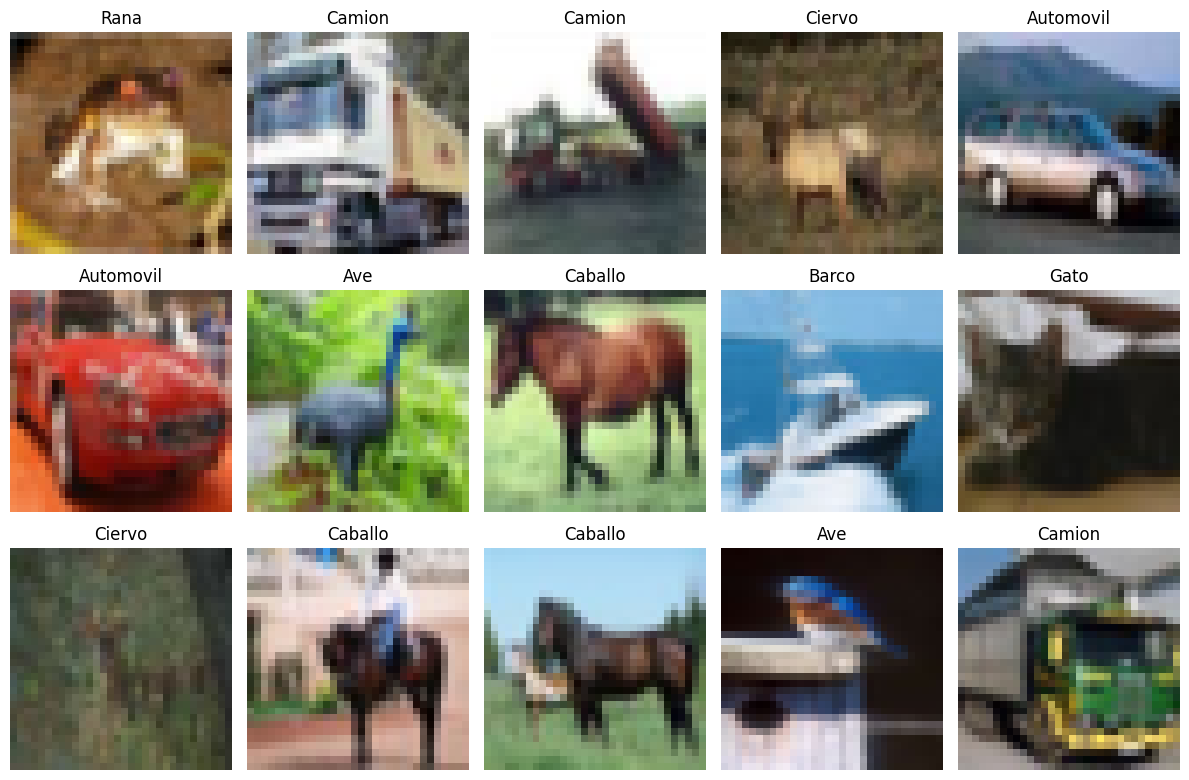

In [12]:
plt.figure(figsize=(12, 8))

for i in range(15):
    plt.subplot(3, 5, i + 1)
    plt.imshow(x_train[i])
    plt.title(class_names[y_train[i][0]])
    plt.axis("off")

plt.tight_layout()
plt.show()

In [13]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split

Avion: 5000 imágenes
Automovil: 5000 imágenes
Ave: 5000 imágenes
Gato: 5000 imágenes
Ciervo: 5000 imágenes
Perro: 5000 imágenes
Rana: 5000 imágenes
Caballo: 5000 imágenes
Barco: 5000 imágenes
Camion: 5000 imágenes


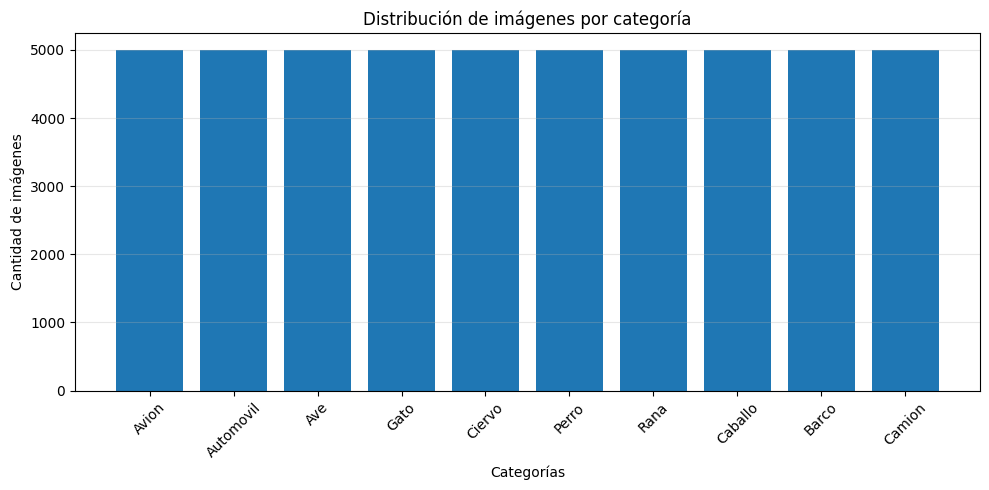

In [14]:
# Contar imágenes por categoría
class_counts = np.bincount(y_train.flatten())

# Mostrar cantidades
for i, count in enumerate(class_counts):
    print(f"{class_names[i]}: {count} imágenes")

# Graficar distribución
plt.figure(figsize=(10, 5))

plt.bar(class_names, class_counts)
plt.title("Distribución de imágenes por categoría")
plt.xlabel("Categorías")
plt.ylabel("Cantidad de imágenes")
plt.xticks(rotation=45)
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

In [15]:
# Normalizar imágenes
x_train = x_train.astype("float32") / 255.0
x_test = x_test.astype("float32") / 255.0

# Dividir los datos de entrenamiento y validación
x_train, x_val, y_train, y_val = train_test_split(
    x_train,
    y_train,
    test_size=0.2,
    random_state=42,
    stratify=y_train
)

# Mostrar dimensiones finales
print("Entrenamiento:", x_train.shape)
print("Validación:", x_val.shape)
print("Prueba:", x_test.shape)

# Comprobar normalización
print("\nRango de valores normalizados:")
print("Mínimo:", x_train.min())
print("Máximo:", x_train.max())

Entrenamiento: (40000, 32, 32, 3)
Validación: (10000, 32, 32, 3)
Prueba: (10000, 32, 32, 3)

Rango de valores normalizados:
Mínimo: 0.0
Máximo: 1.0


In [17]:
# Construcción del modelo CNN
model = tf.keras.Sequential([
    tf.keras.Input(shape=(32, 32, 3)),

    # Primera capa convolucional
    tf.keras.layers.Conv2D(32, (3, 3), activation="relu", padding="same"),
    tf.keras.layers.MaxPooling2D((2, 2)),

    # Segunda capa convolucional
    tf.keras.layers.Conv2D(64, (3, 3), activation="relu", padding="same"),
    tf.keras.layers.MaxPooling2D((2, 2)),

    # Tercera capa convolucional
    tf.keras.layers.Conv2D(128, (3, 3), activation="relu", padding="same"),
    tf.keras.layers.MaxPooling2D((2, 2)),

    # Clasificación
    tf.keras.layers.Flatten(),
    tf.keras.layers.Dense(128, activation="relu"),
    tf.keras.layers.Dropout(0.5),
    tf.keras.layers.Dense(10, activation="softmax")
])

model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_3 (Conv2D)               │ (None, 32, 32, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 16, 16, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 8, 8, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 8, 8, 128)      │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_5 (MaxPooling2D)  │ (None, 4, 4, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 2048)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │       262,272 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 356,810 (1.36 MB)

 Trainable params: 356,810 (1.36 MB)

 Non-trainable params: 0 (0.00 B)

In [18]:
# Compilar el modelo
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

print("Modelo compilado correctamente.")

Modelo compilado correctamente.


In [19]:
# Configuración del entrenamiento
epochs = 20
batch_size = 64

# Entrenar modelo
history = model.fit(
    x_train,
    y_train,
    epochs=epochs,
    batch_size=batch_size,
    validation_data=(x_val, y_val),
    verbose=1
)

Epoch 1/20
625/625 ━━━━━━━━━━━━━━━━━━━━ 18s 14ms/step - accuracy: 0.3658 - loss: 1.7178 - val_accuracy: 0.5110 - val_loss: 1.3525
Epoch 2/20
625/625 ━━━━━━━━━━━━━━━━━━━━ 4s 6ms/step - accuracy: 0.5150 - loss: 1.3513 - val_accuracy: 0.5801 - val_loss: 1.1484
Epoch 3/20
625/625 ━━━━━━━━━━━━━━━━━━━━ 3s 5ms/step - accuracy: 0.5832 - loss: 1.1765 - val_accuracy: 0.6528 - val_loss: 1.0077
Epoch 4/20
625/625 ━━━━━━━━━━━━━━━━━━━━ 4s 6ms/step - accuracy: 0.6274 - loss: 1.0636 - val_accuracy: 0.6548 - val_loss: 0.9520
Epoch 5/20
625/625 ━━━━━━━━━━━━━━━━━━━━ 4s 6ms/step - accuracy: 0.6625 - loss: 0.9681 - val_accuracy: 0.6909 - val_loss: 0.8892
Epoch 6/20
625/625 ━━━━━━━━━━━━━━━━━━━━ 3s 5ms/step - accuracy: 0.6867 - loss: 0.8970 - val_accuracy: 0.7047 - val_loss: 0.8342
Epoch 7/20
625/625 ━━━━━━━━━━━━━━━━━━━━ 3s 5ms/step - accuracy: 0.7086 - loss: 0.8334 - val_accuracy: 0.7144 - val_loss: 0.8072
Epoch 8/20
625/625 ━━━━━━━━━━━━━━━━━━━━ 3s 5ms/step - accuracy: 0.7268 - loss: 0.7822 - val_accuracy: 

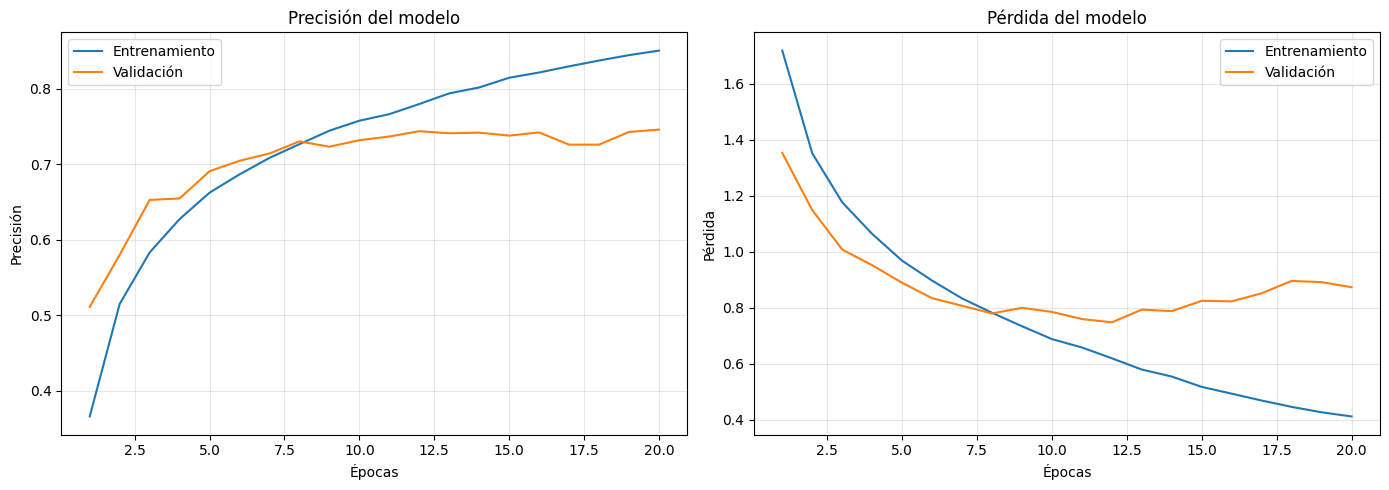

In [20]:
# Obtener métricas del entrenamiento
acc = history.history["accuracy"]
val_acc = history.history["val_accuracy"]

loss = history.history["loss"]
val_loss = history.history["val_loss"]

epochs_range = range(1, len(acc) + 1)

# Crear gráficas
plt.figure(figsize=(14, 5))

# Gráfica de precisión
plt.subplot(1, 2, 1)
plt.plot(epochs_range, acc, label="Entrenamiento")
plt.plot(epochs_range, val_acc, label="Validación")
plt.title("Precisión del modelo")
plt.xlabel("Épocas")
plt.ylabel("Precisión")
plt.legend()
plt.grid(alpha=0.3)

# Gráfica de pérdida
plt.subplot(1, 2, 2)
plt.plot(epochs_range, loss, label="Entrenamiento")
plt.plot(epochs_range, val_loss, label="Validación")
plt.title("Pérdida del modelo")
plt.xlabel("Épocas")
plt.ylabel("Pérdida")
plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

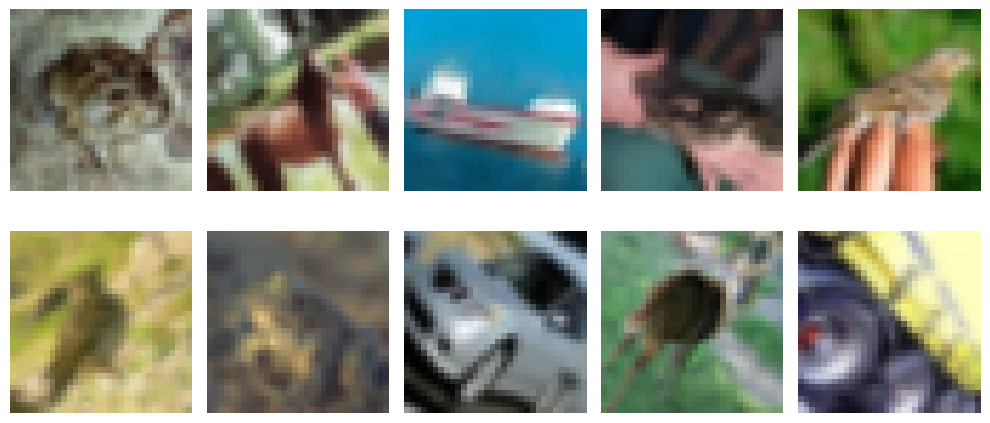

In [21]:
# Aumento de datos
data_augmentation = tf.keras.Sequential([
    tf.keras.layers.RandomFlip("horizontal"),
    tf.keras.layers.RandomRotation(0.1),
    tf.keras.layers.RandomZoom(0.1)
])

# Visualizar imágenes aumentadas
plt.figure(figsize=(10, 5))

for i in range(10):
    augmented_image = data_augmentation(
        tf.expand_dims(x_train[i], axis=0),
        training=True
    )

    plt.subplot(2, 5, i + 1)
    plt.imshow(augmented_image[0].numpy())
    plt.axis("off")

plt.tight_layout()
plt.show()

In [22]:
# Construir segunda versión del modelo
model_v2 = tf.keras.Sequential([
    tf.keras.Input(shape=(32, 32, 3)),

    # Aumento de datos
    data_augmentation,

    # Primera capa convolucional
    tf.keras.layers.Conv2D(32, (3, 3), activation="relu", padding="same"),
    tf.keras.layers.MaxPooling2D((2, 2)),

    # Segunda capa convolucional
    tf.keras.layers.Conv2D(64, (3, 3), activation="relu", padding="same"),
    tf.keras.layers.MaxPooling2D((2, 2)),

    # Tercera capa convolucional
    tf.keras.layers.Conv2D(128, (3, 3), activation="relu", padding="same"),
    tf.keras.layers.MaxPooling2D((2, 2)),

    # Clasificación
    tf.keras.layers.Flatten(),
    tf.keras.layers.Dense(128, activation="relu"),
    tf.keras.layers.Dropout(0.5),
    tf.keras.layers.Dense(10, activation="softmax")
])

model_v2.summary()

Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ sequential_2 (Sequential)       │ (None, 32, 32, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_6 (Conv2D)               │ (None, 32, 32, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_6 (MaxPooling2D)  │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_7 (Conv2D)               │ (None, 16, 16, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_7 (MaxPooling2D)  │ (None, 8, 8, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_8 (Conv2D)               │ (None, 8, 8, 128)      │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_8 (MaxPooling2D)  │ (None, 4, 4, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_2 (Flatten)             │ (None, 2048)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 128)            │       262,272 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 356,810 (1.36 MB)

 Trainable params: 356,810 (1.36 MB)

 Non-trainable params: 0 (0.00 B)

In [23]:
model_v2.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

print("Segunda versión del modelo compilada correctamente.")

Segunda versión del modelo compilada correctamente.


In [24]:
# Configurar callbacks
early_stopping = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True
)

reduce_lr = tf.keras.callbacks.ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.5,
    patience=2,
    min_lr=0.00001
)

callbacks = [early_stopping, reduce_lr]

In [25]:
history_v2 = model_v2.fit(
    x_train,
    y_train,
    epochs=30,
    batch_size=64,
    validation_data=(x_val, y_val),
    callbacks=callbacks,
    verbose=1
)

Epoch 1/30
625/625 ━━━━━━━━━━━━━━━━━━━━ 10s 8ms/step - accuracy: 0.3371 - loss: 1.7981 - val_accuracy: 0.4838 - val_loss: 1.4176 - learning_rate: 0.0010
Epoch 2/30
625/625 ━━━━━━━━━━━━━━━━━━━━ 6s 9ms/step - accuracy: 0.4550 - loss: 1.5028 - val_accuracy: 0.5303 - val_loss: 1.3114 - learning_rate: 0.0010
Epoch 3/30
625/625 ━━━━━━━━━━━━━━━━━━━━ 9s 8ms/step - accuracy: 0.5032 - loss: 1.3835 - val_accuracy: 0.5864 - val_loss: 1.1534 - learning_rate: 0.0010
Epoch 4/30
625/625 ━━━━━━━━━━━━━━━━━━━━ 6s 9ms/step - accuracy: 0.5399 - loss: 1.3026 - val_accuracy: 0.5828 - val_loss: 1.2045 - learning_rate: 0.0010
Epoch 5/30
625/625 ━━━━━━━━━━━━━━━━━━━━ 5s 8ms/step - accuracy: 0.5590 - loss: 1.2433 - val_accuracy: 0.5925 - val_loss: 1.1551 - learning_rate: 0.0010
Epoch 6/30
625/625 ━━━━━━━━━━━━━━━━━━━━ 6s 9ms/step - accuracy: 0.5904 - loss: 1.1589 - val_accuracy: 0.6589 - val_loss: 0.9664 - learning_rate: 5.0000e-04
Epoch 7/30
625/625 ━━━━━━━━━━━━━━━━━━━━ 5s 8ms/step - accuracy: 0.6007 - loss: 1.13

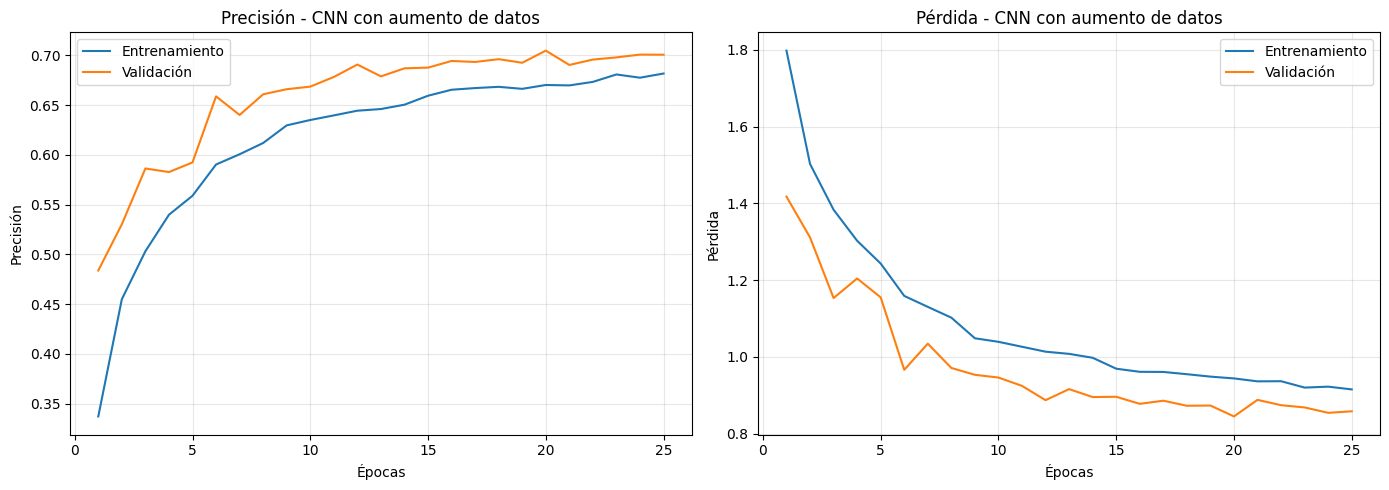

In [26]:
# Obtener métricas del segundo entrenamiento
acc_v2 = history_v2.history["accuracy"]
val_acc_v2 = history_v2.history["val_accuracy"]

loss_v2 = history_v2.history["loss"]
val_loss_v2 = history_v2.history["val_loss"]

epochs_range = range(1, len(acc_v2) + 1)

plt.figure(figsize=(14, 5))

# Precisión
plt.subplot(1, 2, 1)
plt.plot(epochs_range, acc_v2, label="Entrenamiento")
plt.plot(epochs_range, val_acc_v2, label="Validación")
plt.title("Precisión - CNN con aumento de datos")
plt.xlabel("Épocas")
plt.ylabel("Precisión")
plt.legend()
plt.grid(alpha=0.3)

# Pérdida
plt.subplot(1, 2, 2)
plt.plot(epochs_range, loss_v2, label="Entrenamiento")
plt.plot(epochs_range, val_loss_v2, label="Validación")
plt.title("Pérdida - CNN con aumento de datos")
plt.xlabel("Épocas")
plt.ylabel("Pérdida")
plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [27]:
# Evaluar primera versión
test_loss_v1, test_acc_v1 = model.evaluate(
    x_test, y_test, verbose=0
)

# Evaluar segunda versión
test_loss_v2, test_acc_v2 = model_v2.evaluate(
    x_test, y_test, verbose=0
)

# Mostrar resultados
print("RESULTADOS EN EL CONJUNTO DE PRUEBA")

print("\nPrimera CNN:")
print(f"Precisión: {test_acc_v1 * 100:.2f}%")
print(f"Pérdida: {test_loss_v1:.4f}")

print("\nSegunda CNN con Data Augmentation:")
print(f"Precisión: {test_acc_v2 * 100:.2f}%")
print(f"Pérdida: {test_loss_v2:.4f}")

RESULTADOS EN EL CONJUNTO DE PRUEBA

Primera CNN:
Precisión: 74.82%
Pérdida: 0.9004

Segunda CNN con Data Augmentation:
Precisión: 70.32%
Pérdida: 0.8436


313/313 ━━━━━━━━━━━━━━━━━━━━ 3s 6ms/step


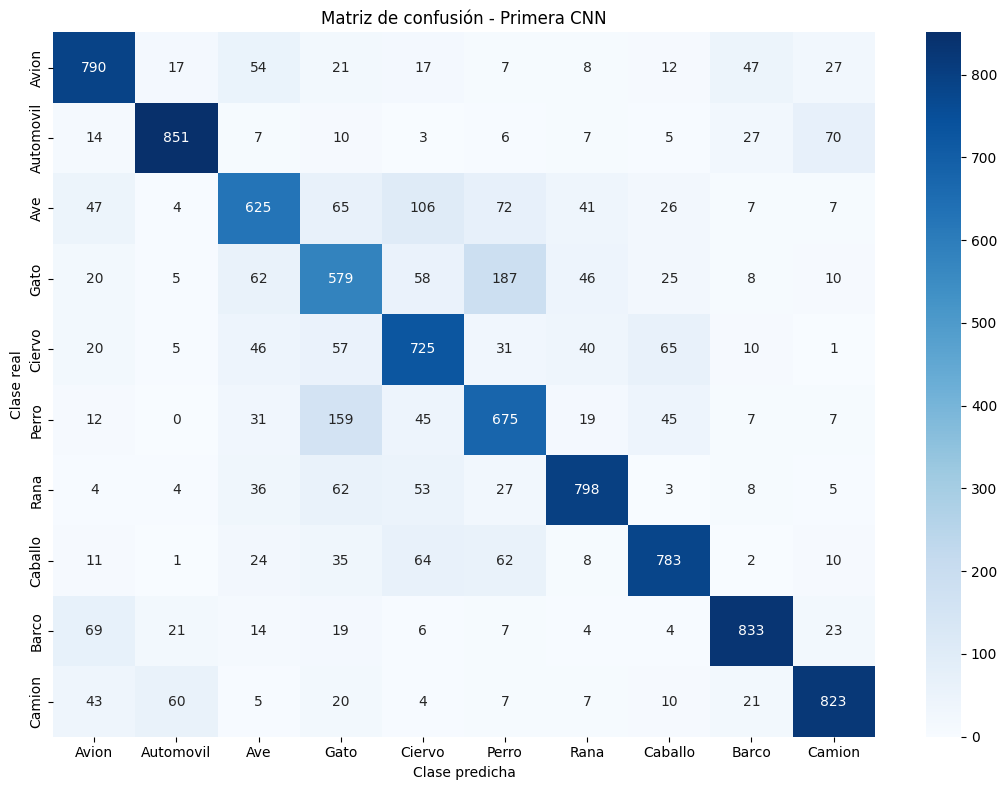

In [28]:
from sklearn.metrics import confusion_matrix, classification_report

# Obtener predicciones del modelo seleccionado
y_pred = model.predict(x_test)

# Convertir probabilidades en clases
y_pred_classes = np.argmax(y_pred, axis=1)

# Preparar etiquetas reales
y_true = y_test.flatten()

# Calcular matriz de confusión
cm = confusion_matrix(y_true, y_pred_classes)

# Visualizar matriz
plt.figure(figsize=(11, 8))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)

plt.title("Matriz de confusión - Primera CNN")
plt.xlabel("Clase predicha")
plt.ylabel("Clase real")
plt.tight_layout()
plt.show()

In [29]:
print("Reporte de clasificación:\n")

print(
    classification_report(
        y_true,
        y_pred_classes,
        target_names=class_names
    )
)

Reporte de clasificación:

              precision    recall  f1-score   support

       Avion       0.77      0.79      0.78      1000
   Automovil       0.88      0.85      0.86      1000
         Ave       0.69      0.62      0.66      1000
        Gato       0.56      0.58      0.57      1000
      Ciervo       0.67      0.72      0.70      1000
       Perro       0.62      0.68      0.65      1000
        Rana       0.82      0.80      0.81      1000
     Caballo       0.80      0.78      0.79      1000
       Barco       0.86      0.83      0.85      1000
      Camion       0.84      0.82      0.83      1000

    accuracy                           0.75     10000
   macro avg       0.75      0.75      0.75     10000
weighted avg       0.75      0.75      0.75     10000



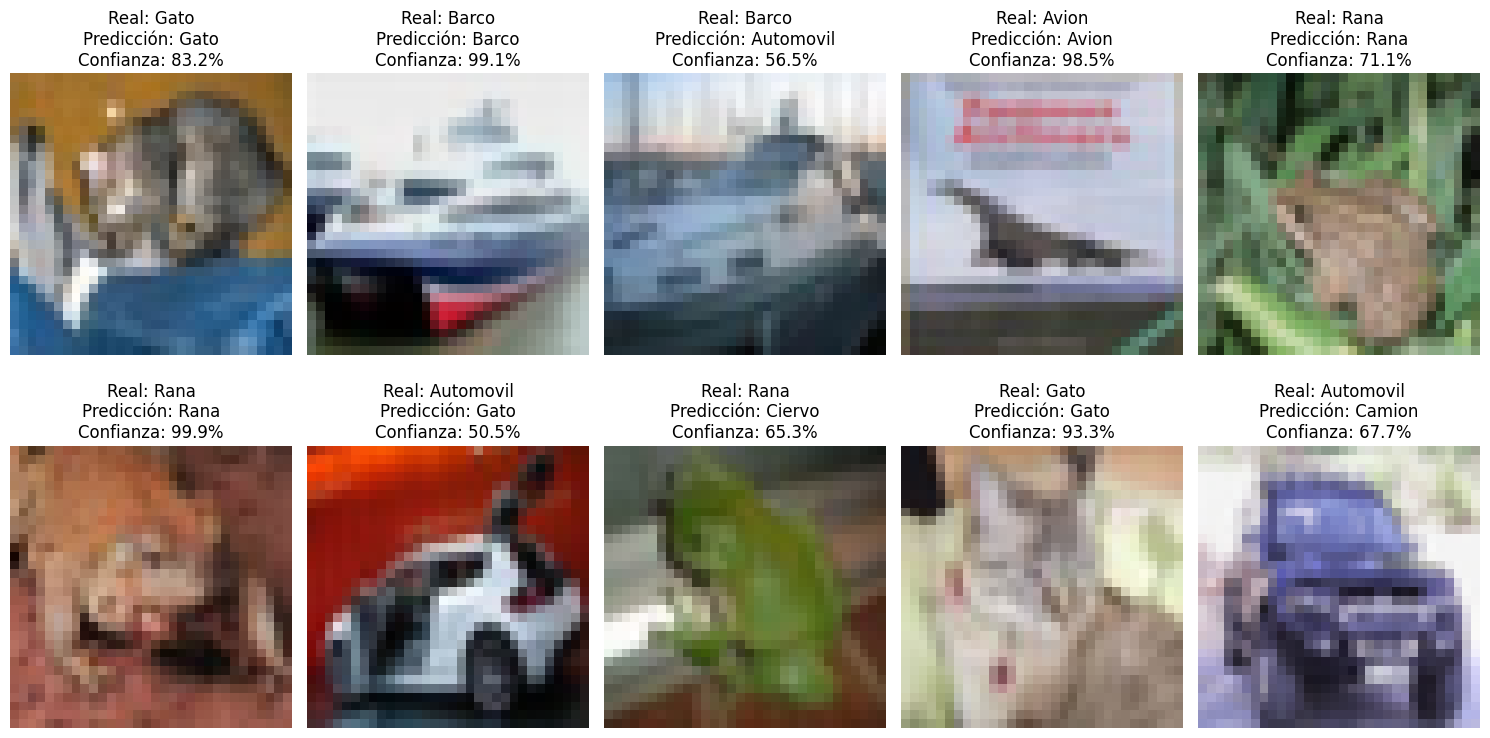

In [30]:
plt.figure(figsize=(15, 8))

for i in range(10):
    plt.subplot(2, 5, i + 1)

    plt.imshow(x_test[i])

    real = class_names[y_true[i]]
    predicha = class_names[y_pred_classes[i]]
    confianza = np.max(y_pred[i]) * 100

    plt.title(
        f"Real: {real}\n"
        f"Predicción: {predicha}\n"
        f"Confianza: {confianza:.1f}%"
    )

    plt.axis("off")

plt.tight_layout()
plt.show()

In [31]:
import os
import json

# Crear carpeta para guardar el modelo
os.makedirs("/content/models", exist_ok=True)

# Guardar primera CNN
model.save("/content/models/cnn_model.keras")

# Guardar nombres de las categorías
with open("/content/models/class_names.json", "w", encoding="utf-8") as file:
    json.dump(class_names, file, ensure_ascii=False, indent=4)

# Guardar métricas de evaluación
metrics = {
    "model": "CNN",
    "dataset": "CIFAR-10",
    "test_accuracy": float(test_acc_v1),
    "test_loss": float(test_loss_v1),
    "classes": class_names
}

with open("/content/models/metrics.json", "w", encoding="utf-8") as file:
    json.dump(metrics, file, ensure_ascii=False, indent=4)

print("Archivos guardados correctamente.")

Archivos guardados correctamente.


In [32]:
from google.colab import files

files.download("/content/models/cnn_model.keras")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [33]:
files.download("/content/models/class_names.json")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [34]:
files.download("/content/models/metrics.json")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>